# Étape 2 : test visuel des 5 descripteurs

Ce notebook vérifie **à l'œil** que chaque descripteur mesure bien ce qu'il doit mesurer :

| Descripteur | Ce qu'on doit voir |
|---|---|
| Histogramme HSV | les teintes majoritaires de l'image ressortent |
| Moments de couleur | moyenne / dispersion / asymétrie cohérentes avec l'image |
| Couleurs dominantes | un nuancier qui « ressemble » à l'image |
| GLCM | contraste élevé pour une image texturée, faible pour une image lisse |
| LBP | l'image LBP fait ressortir les contours et micro-motifs |

Le code des descripteurs est dans `cbir_api/cbir/descriptors.py` ; ce notebook ne fait que l'appeler.
Si la base GHIM-10K est présente dans `data/`, on prend des images au hasard dedans ; sinon on utilise
les images d'exemple de scikit-image.

In [1]:
import sys, time, random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "cbir_api"))       # pour importer le paquet "cbir"
from cbir import descriptors as D

print("Dimension du vecteur final :", D.FEATURE_DIM)
for name, s in D.descriptor_slices().items():
    print(f"  {name:16s} composantes {s.start:3d} à {s.stop - 1:3d}  ({s.stop - s.start} valeurs)")

Dimension du vecteur final : 174
  color_hist       composantes   0 à 127  (128 valeurs)
  color_moments    composantes 128 à 136  (9 valeurs)
  dominant_colors  composantes 137 à 156  (20 valeurs)
  glcm             composantes 157 à 163  (7 valeurs)
  lbp              composantes 164 à 173  (10 valeurs)


## 1. Charger quelques images

In [2]:
DATA = ROOT / "data"
files = sorted(p for p in DATA.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}) if DATA.exists() else []

if files:
    random.seed(0)
    sample_files = random.sample(files, 4)
    images = {p.parent.name + "/" + p.name: D.load_image(p) for p in sample_files}
    print(f"{len(files)} images trouvées dans data/ ; 4 tirées au hasard.")
else:
    from skimage import data as skdata
    rgb = {"astronaute": skdata.astronaut(), "café": skdata.coffee(), "chat": skdata.chelsea(), "fusée": skdata.rocket()}
    images = {k: cv2.cvtColor(v, cv2.COLOR_RGB2BGR) for k, v in rgb.items()}   # scikit-image donne du RGB, OpenCV attend du BGR
    print("Base GHIM-10K absente : utilisation des images d'exemple de scikit-image.")

Base GHIM-10K absente : utilisation des images d'exemple de scikit-image.


## 2. Fonction d'affichage

Pour l'histogramme HSV, on additionne les cases sur S et V pour ne garder que les **8 teintes** :
c'est plus lisible que 128 barres. Chaque barre est coloriée avec la teinte qu'elle représente.

In [3]:
def hue_colors(n_bins):
    """Couleur RGB (0-1) du centre de chacune des n_bins cases de teinte."""
    h = ((np.arange(n_bins) + 0.5) * 180 / n_bins).astype(np.uint8)
    hsv = np.stack([h, np.full_like(h, 255), np.full_like(h, 255)], axis=1).reshape(1, -1, 3)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB).reshape(-1, 3) / 255


def show_descriptors(title, img_bgr):
    img = D.prepare_image(img_bgr)
    res = D.compute_all(img)
    fig, ax = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(title, fontsize=14)

    ax[0, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0, 0].set_title("Image (256x256)"); ax[0, 0].axis("off")

    hist = np.array(res["color_histogram"]["values"]).reshape(D.HSV_BINS)
    hue = hist.sum(axis=(1, 2))                                # somme sur S et V
    ax[0, 1].bar(range(len(hue)), hue, color=hue_colors(len(hue)), edgecolor="k")
    ax[0, 1].set_title("Histogramme : répartition des teintes"); ax[0, 1].set_xlabel("case de teinte")

    left = 0
    for c in res["dominant_colors"]:
        ax[0, 2].barh(0, c["proportion"], left=left, color=np.array(c["rgb"]) / 255, edgecolor="k")
        if c["proportion"] > 0.07:
            ax[0, 2].text(left + c["proportion"] / 2, 0, f'{c["hex"]}\n{c["proportion"]:.0%}', ha="center", va="center", fontsize=8,
                          color="white" if sum(c["rgb"]) < 380 else "black")
        left += c["proportion"]
    ax[0, 2].set_xlim(0, 1); ax[0, 2].set_yticks([]); ax[0, 2].set_title("Couleurs dominantes (K-means, k=5)")

    g = res["glcm"]
    ax[1, 0].axis("off"); ax[1, 0].set_title("GLCM (moyenne sur 3 distances x 4 angles)")
    ax[1, 0].table(cellText=[[k, f"{v:.4f}"] for k, v in g.items()], colLabels=["propriété", "valeur"], loc="center", cellLoc="left").scale(1, 1.6)

    ax[1, 1].imshow(D.lbp_image(img), cmap="gray"); ax[1, 1].set_title("Image LBP (étiquettes 0 à 9)"); ax[1, 1].axis("off")

    ax[1, 2].bar(range(10), res["lbp"]["values"], color="steelblue", edgecolor="k")
    ax[1, 2].set_xticks(range(10)); ax[1, 2].set_title("Histogramme LBP uniforme"); ax[1, 2].set_xlabel("motif (9 = non uniforme)")
    plt.tight_layout(); plt.show()

    m = res["color_moments"]
    print("Moments de couleur :", {ch: {k: round(v, 1) for k, v in d.items()} for ch, d in m.items()})

## 3. Les descripteurs de chaque image

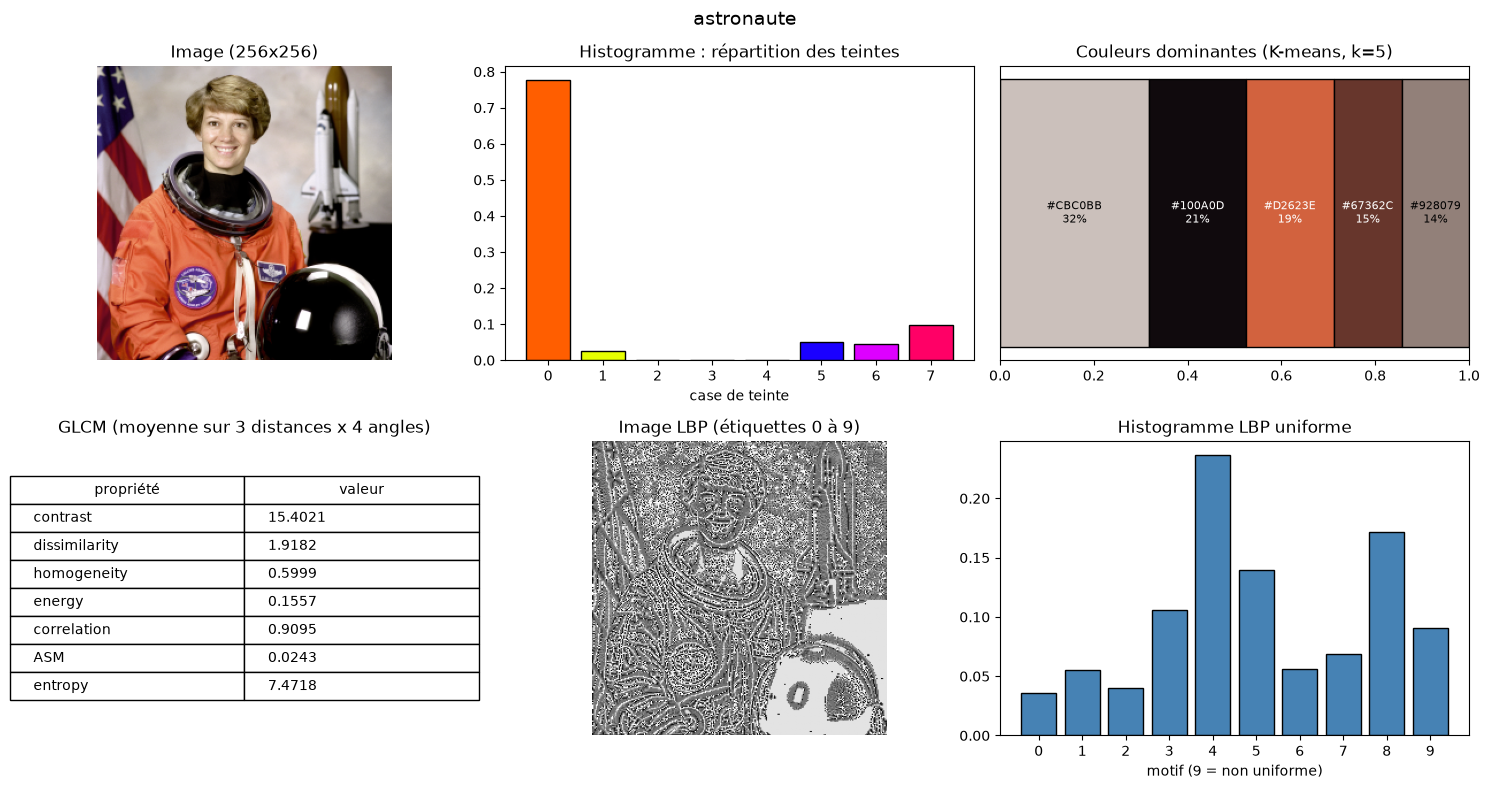

Moments de couleur : {'H': {'mean': 37.6, 'std': 58.6, 'skewness': 67.9}, 'S': {'mean': 89.8, 'std': 86.6, 'skewness': 67.9}, 'V': {'mean': 143.0, 'std': 80.8, 'skewness': -70.2}}


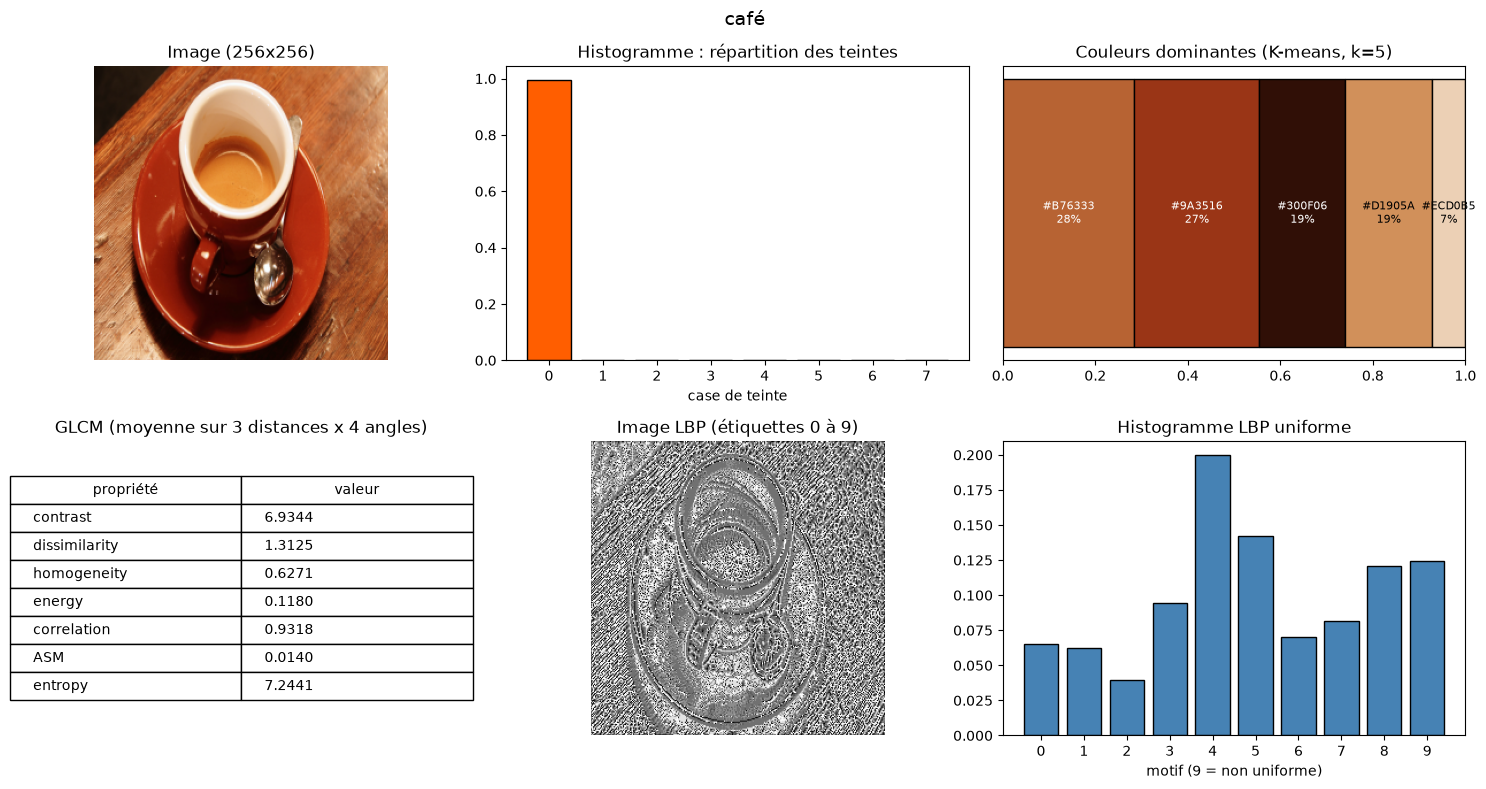

Moments de couleur : {'H': {'mean': 10.0, 'std': 8.7, 'skewness': 19.4}, 'S': {'mean': 184.2, 'std': 53.4, 'skewness': -55.8}, 'V': {'mean': 158.6, 'std': 62.2, 'skewness': -60.6}}


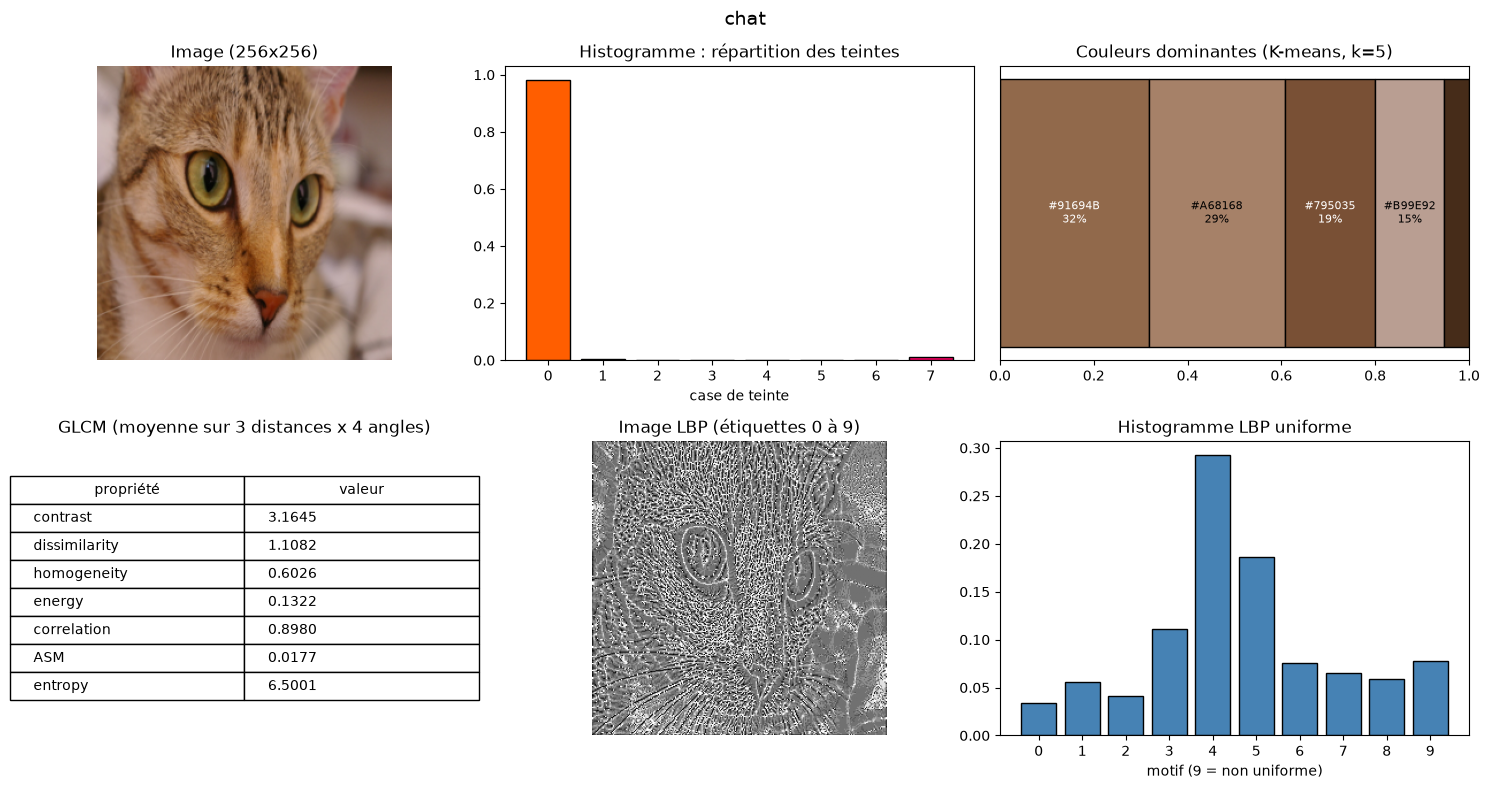

Moments de couleur : {'H': {'mean': 13.3, 'std': 17.6, 'skewness': 36.3}, 'S': {'mean': 109.8, 'std': 43.8, 'skewness': 26.7}, 'V': {'mean': 147.7, 'std': 31.6, 'skewness': -32.3}}


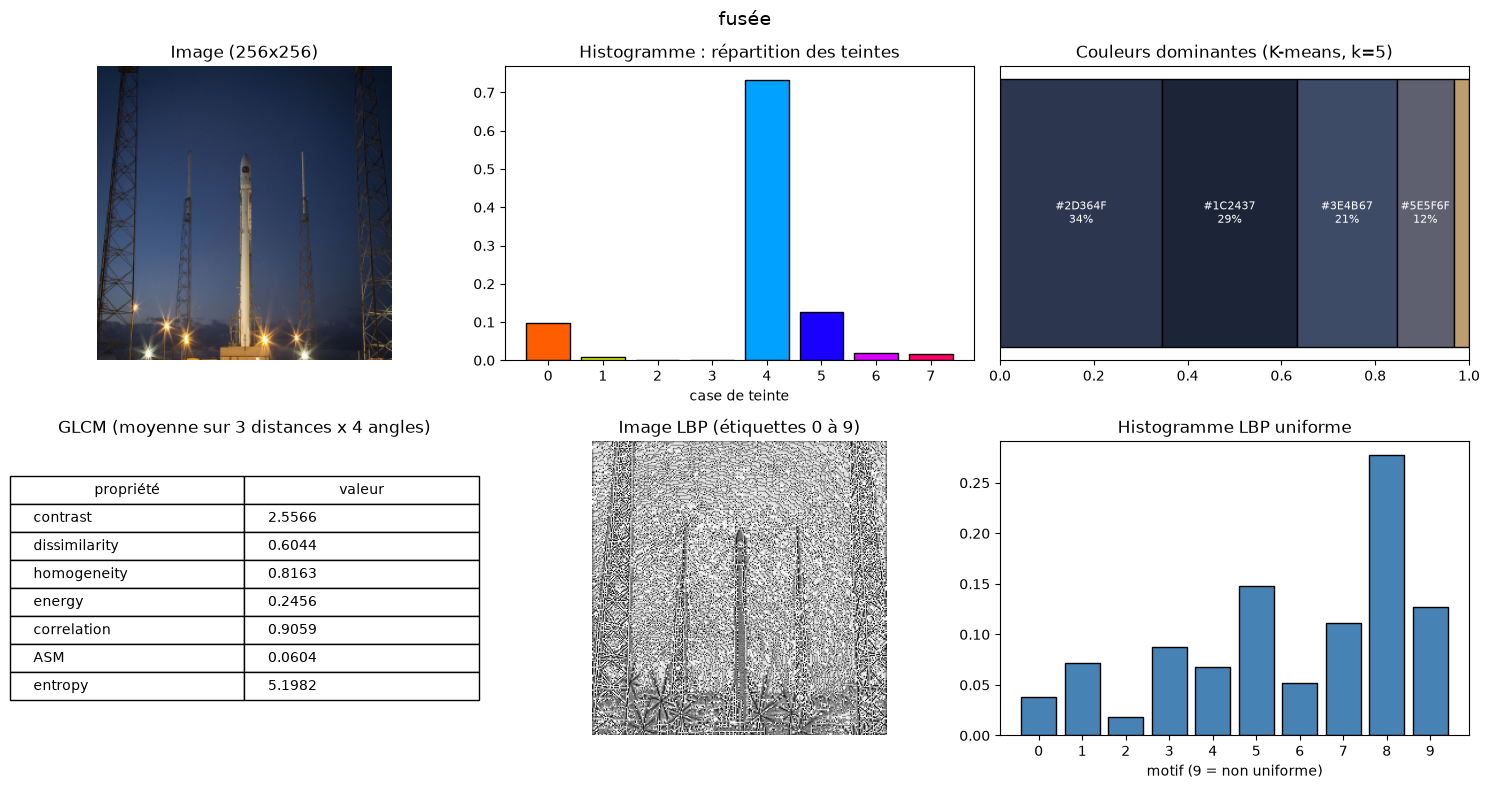

Moments de couleur : {'H': {'mean': 102.4, 'std': 31.5, 'skewness': -40.0}, 'S': {'mean': 116.9, 'std': 42.6, 'skewness': -36.9}, 'V': {'mean': 86.9, 'std': 32.9, 'skewness': 35.4}}


In [4]:
for name, img in images.items():
    show_descriptors(name, img)

## 4. Vérification : texture lisse vs texture rugueuse

Une image floutée doit avoir un **contraste GLCM plus faible** et une **homogénéité plus forte**
que l'originale. Si ce n'est pas le cas, le descripteur est mal calculé.

In [5]:
img = D.prepare_image(next(iter(images.values())))
blur = cv2.GaussianBlur(img, (0, 0), 3)
for label, im in [("originale", img), ("floutée", blur)]:
    g = D.glcm_features(im)
    print(f"{label:10s} contraste = {g['contrast']:8.3f}   homogénéité = {g['homogeneity']:.3f}   entropie = {g['entropy']:.3f}")

originale  contraste =   15.402   homogénéité = 0.600   entropie = 7.472
floutée    contraste =    2.140   homogénéité = 0.696   entropie = 6.729


## 5. Temps de calcul

Pour savoir combien de temps prendra l'indexation des 10 000 images (étape 3).

In [6]:
imgs = list(images.values()) * 5
t0 = time.perf_counter()
for im in imgs:
    D.extract_feature_vector(im)
per_image = (time.perf_counter() - t0) / len(imgs)
print(f"{per_image * 1000:.0f} ms par image  ->  environ {per_image * 10000 / 60:.1f} min pour 10 000 images sur 1 cœur")

26 ms par image  ->  environ 4.3 min pour 10 000 images sur 1 cœur
